# Serie I: perfil de calidad y primera EDA

Este notebook perfila el CSV original sin modificarlo; el ETL aplica después las exclusiones analíticas. Separamos hallazgos descriptivos de decisiones de limpieza: algunas celdas fuente de `TRS_TON` tienen dos números y hay filas repetidas. El análisis conserva el texto original, separa el prefijo y usa solo el componente numérico final en la columna analítica `TRS_TON`.

La unidad de `T_SPACRE` se toma de la ficha oficial USDA-ARS (libras de azúcar por acre), según la decisión documentada al inicio del README.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 50)
sns.set_theme(style='whitegrid')

DATA_PATH = Path('../data/raw/louisiana_sugarcane_2010_2021.csv')
if not DATA_PATH.exists():
    DATA_PATH = Path('data/raw/louisiana_sugarcane_2010_2021.csv')
if not DATA_PATH.exists():
    raise FileNotFoundError('Descarga primero los datos con: python scripts/descargar_serie1.py')

# dtype=str y keep_default_na=False preservan literalmente marcadores y valores inusuales.
raw = pd.read_csv(DATA_PATH, dtype=str, keep_default_na=False)
print(f'Archivo: {DATA_PATH.as_posix()}')
print(f'Filas: {len(raw):,}; columnas: {len(raw.columns)}')
print(f'Columnas: {list(raw.columns)}')

Archivo: ../data/raw/louisiana_sugarcane_2010_2021.csv
Filas: 29,529; columnas: 15
Columnas: ['CLONE', 'YEAR', 'STAGE', 'LOC', 'CROP', 'REP', 'T_SPACRE', 'TRS_TON', 'TCA', 'POPN', 'MSTWT', 'FIBER', 'Unnamed: 12', 'Unnamed: 13', 'Unnamed: 14']


## 1. Marcadores, columnas auxiliares y repetidos

Los puntos y celdas vacías se reportan como aparecen en el archivo. Todavía no se imputan. Las tres columnas sin nombre se conservan en la lectura para no perder las seis notas al final del CSV.

In [2]:
marker_table = pd.DataFrame({
    'vacios': raw.apply(lambda col: col.str.strip().eq('').sum()),
    'punto': raw.apply(lambda col: col.str.strip().eq('.').sum()),
    'valores_distintos_no_vacios': raw.apply(lambda col: col.str.strip().ne('').sum()),
})
marker_table

,vacios,punto,valores_distintos_no_vacios
CLONE,0,0,29529
YEAR,0,0,29529
STAGE,0,0,29529
LOC,0,0,29529
CROP,0,0,29529
REP,0,0,29529
T_SPACRE,0,175,29529
TRS_TON,0,91,29529
TCA,0,166,29529
POPN,0,3533,29529


In [3]:
key = ['CLONE', 'YEAR', 'STAGE', 'LOC', 'CROP', 'REP']
measurement_cols = ['T_SPACRE', 'TRS_TON', 'TCA', 'POPN', 'MSTWT', 'FIBER']
exact_extra_rows = int(raw.duplicated().sum())
repeated_key_mask = raw.duplicated(key, keep=False)
key_groups = raw.loc[repeated_key_mask].groupby(key, dropna=False)[measurement_cols].nunique(dropna=False)
different_measure_groups = int((key_groups.gt(1).any(axis=1)).sum())
print(f'Filas completas repetidas (copias posteriores): {exact_extra_rows:,}')
print(f'Filas que pertenecen a grupos repetidos por clave candidata: {int(repeated_key_mask.sum()):,}')
print(f'Grupos de esa clave con mediciones distintas: {different_measure_groups:,}')
print('Este perfil conserva la fuente intacta; el ETL separa las copias exactas adicionales para el análisis.')

Filas completas repetidas (copias posteriores): 126
Filas que pertenecen a grupos repetidos por clave candidata: 476
Grupos de esa clave con mediciones distintas: 112
Este perfil conserva la fuente intacta; el ETL separa las copias exactas adicionales para el análisis.


## Auditoría de claves repetidas con mediciones distintas

Se quitan solo las copias exactas adicionales para examinar las claves repetidas que permanecen. La clave `(CLONE, YEAR, STAGE, LOC, CROP, REP)` es candidata: el archivo no confirma que sea un identificador único de parcela. Esta auditoría describe las diferencias sin elegir, promediar ni excluir observaciones.

In [4]:
fuente_sin_copias = raw.loc[~raw.duplicated(keep="first")].copy()
filas_clave_repetida = fuente_sin_copias.loc[fuente_sin_copias.duplicated(key, keep=False)].copy()
tamano_grupos = filas_clave_repetida.groupby(key, dropna=False).size()
variacion_mediciones = filas_clave_repetida.groupby(key, dropna=False)[measurement_cols].nunique(dropna=False)
grupos = filas_clave_repetida[key].drop_duplicates()

print(f"Filas analíticas después de quitar copias exactas: {len(fuente_sin_copias):,}")
print(f"Filas en grupos de clave repetida: {len(filas_clave_repetida):,}")
print(f"Grupos: {len(tamano_grupos):,}; tamaños observados: {tamano_grupos.value_counts().sort_index().to_dict()}")
print(f"Etapas presentes: {grupos['STAGE'].value_counts().sort_index().to_dict()}")

print("Grupos por año:")
print(grupos.groupby("YEAR").size().rename("grupos").to_string())
print("Grupos por localidad:")
print(grupos.groupby("LOC").size().rename("grupos").to_string())
print("Grupos por clon:")
print(grupos.groupby("CLONE").size().sort_values(ascending=False).to_string())
print("Grupos con mediciones distintas por variable:")
print(variacion_mediciones.gt(1).sum().rename("grupos_con_diferencias").to_string())

filas_clave_repetida = filas_clave_repetida.assign(FIBER_disponible=filas_clave_repetida["FIBER"].str.strip().ne(""))
fibra_por_grupo = filas_clave_repetida.groupby(key, dropna=False)["FIBER_disponible"].sum()
print("Grupos según cuántas filas tienen FIBER disponible:")
print(fibra_por_grupo.value_counts().sort_index().rename_axis("filas_con_FIBER").to_string())

Filas analíticas después de quitar copias exactas: 29,403
Filas en grupos de clave repetida: 224
Grupos: 112; tamaños observados: {2: 112}
Etapas presentes: {'3': 112}
Grupos por año:
YEAR
2010    20
2011    24
2012    18
2013    10
2020    11
2021    29
Grupos por localidad:
LOC
AFL    90
NIB     4
SGL    18
Grupos por clon:
CLONE
HOCP96-540    24
L99-226       18
L01-283       16
L01-299       14
L99-233       12
HOCP09-804    10
HO12-615       8
L12-201        8
LCP85-384      2
Grupos con mediciones distintas por variable:
T_SPACRE    112
TRS_TON     112
TCA         111
POPN        112
MSTWT       112
FIBER        94
Grupos según cuántas filas tienen FIBER disponible:
filas_con_FIBER
0    18
1    61
2    33


Los 112 grupos tienen dos filas y todos corresponden a `STAGE=3`. En cada grupo difieren `T_SPACRE`, `TRS_TON`, `POPN` y `MSTWT`; en 111 grupos también difiere `TCA` y en 94 difiere `FIBER`. Los pares se limitan a nueve clones; dos coinciden con los controles que identifica el artículo (HOCP96-540 y L01-299), pero los otros siete también tienen claves repetidas. La disponibilidad de `FIBER` tampoco identifica una fila preferible: hay grupos con cero, una o dos filas con ese dato.

La ficha del [USDA-ARS](https://catalog.data.gov/dataset/louisiana-sugarcane-yield-data-2010-2021-collected-for-the-louisiana-variety-development-p) describe repeticiones variables en el conjunto. Un artículo del mismo programa señala dos repeticiones para etapa 3, pero no explica estas claves repetidas ni documenta otro identificador aplicable a este CSV ([Shahi et al., 2025](https://acsess.onlinelibrary.wiley.com/doi/10.1002/tpg2.20545)). La causa queda sin resolver: puede faltar una dimensión del ensayo o haber un problema en el archivo.

Decisión provisional: mantener ambas observaciones y marcarlas para revisión. Eliminarlas o promediarlas sin identificar la unidad experimental podría borrar mediciones legítimas o sesgar resultados. Para resolverlo se necesita un diccionario o confirmación del responsable de los datos.

## Comparación con réplicas y antecedentes del mismo clon

Para comparar sin mezclar clones o ambientes, se usa como contexto el mismo `CLONE`, `STAGE`, `LOC` y `CROP`. En el mismo año se buscan otras réplicas que no estén marcadas por la misma colisión. Como respaldo histórico, se usan años anteriores del mismo contexto y solo filas con clave candidata no repetida. Se exige historial en al menos dos años y se compara cada medición con el rango observado, la mediana y el rango intercuartílico (IQR); son referencias descriptivas, no reglas para eliminar datos. `T_SPACRE` es el resultado principal; `TRS_TON` y `TCA` se revisan por separado porque forman su relación dimensional.

In [5]:
RUTA_ETL = Path("../data/processed/serie1_etl_provisional.csv")
if not RUTA_ETL.exists():
    RUTA_ETL = Path("data/processed/serie1_etl_provisional.csv")
if not RUTA_ETL.exists():
    raise FileNotFoundError("Ejecuta primero: python scripts/etl_serie1.py")

datos_etl = pd.read_csv(RUTA_ETL, low_memory=False)
filas_conflictivas = datos_etl.loc[datos_etl["CLAVE_CANDIDATA_REPETIDA"]]
filas_referencia = datos_etl.loc[~datos_etl["CLAVE_CANDIDATA_REPETIDA"]]
comparaciones = []
referencias_misma_zafra = []
variables_comparadas = ["T_SPACRE", "TRS_TON", "TCA", "POPN", "MSTWT", "FIBER"]

for clave, par in filas_conflictivas.groupby(key, dropna=False):
    clon, anio, etapa, localidad, crop, rep = clave
    mismo_contexto = datos_etl.loc[
        datos_etl["CLONE"].eq(clon)
        & datos_etl["YEAR"].eq(anio)
        & datos_etl["STAGE"].eq(etapa)
        & datos_etl["LOC"].eq(localidad)
        & datos_etl["CROP"].eq(crop)
    ]
    otra_rep_limpia = mismo_contexto.loc[
        mismo_contexto["REP"].ne(rep)
        & ~mismo_contexto["CLAVE_CANDIDATA_REPETIDA"]
    ]
    referencias_misma_zafra.append(len(otra_rep_limpia))

    historial = filas_referencia.loc[
        filas_referencia["CLONE"].eq(clon)
        & filas_referencia["STAGE"].eq(etapa)
        & filas_referencia["LOC"].eq(localidad)
        & filas_referencia["CROP"].eq(crop)
        & filas_referencia["YEAR"].lt(anio)
    ]
    if historial["YEAR"].nunique() < 2:
        continue

    for variable in variables_comparadas:
        valores_actuales = pd.to_numeric(par[variable], errors="coerce").dropna()
        valores_previos = pd.to_numeric(historial[variable], errors="coerce").dropna()
        if len(valores_actuales) != 2 or len(valores_previos) < 2:
            continue
        mediana_previa = valores_previos.median()
        iqr_previo = valores_previos.quantile(0.75) - valores_previos.quantile(0.25)
        if mediana_previa == 0:
            continue
        dentro_rango = valores_actuales.between(valores_previos.min(), valores_previos.max()).sum()
        desviacion_pct = (valores_actuales.sub(mediana_previa).abs().div(abs(mediana_previa)) * 100).median()
        comparaciones.append({
            "variable": variable,
            "filas_dentro_rango_previo": int(dentro_rango),
            "desviacion_mediana_pct": desviacion_pct,
            "desviacion_mediana_iqr": (valores_actuales.sub(mediana_previa).abs().div(iqr_previo)).median(),
        })

comparaciones = pd.DataFrame(comparaciones)
print("Filas comparables de otra REP no marcada, en el mismo año y contexto:")
print(pd.Series(referencias_misma_zafra).value_counts().sort_index().rename_axis("filas_referencia").to_string())
print("Pares con al menos dos años previos no ambiguos por variable:")
print(comparaciones.groupby("variable").size().to_dict())

resumen_contextual = pd.crosstab(comparaciones["variable"], comparaciones["filas_dentro_rango_previo"])
resumen_contextual = resumen_contextual.rename(columns={0: "ninguna", 1: "una", 2: "ambas"})
resumen_contextual["pares_comparables"] = comparaciones.groupby("variable").size()
resumen_contextual["desviacion_mediana_pct"] = comparaciones.groupby("variable")["desviacion_mediana_pct"].median().round(1)
resumen_contextual["distancia_mediana_iqr"] = comparaciones.groupby("variable")["desviacion_mediana_iqr"].median().round(2)
print("Comparación contra el rango de años previos del mismo clon, etapa, localidad y corte:")
print(resumen_contextual.to_string())

Filas comparables de otra REP no marcada, en el mismo año y contexto:
filas_referencia
0    109
1      3
Pares con al menos dos años previos no ambiguos por variable:
{'FIBER': 22, 'MSTWT': 26, 'POPN': 1, 'TCA': 23, 'TRS_TON': 26, 'T_SPACRE': 26}
Comparación contra el rango de años previos del mismo clon, etapa, localidad y corte:
filas_dentro_rango_previo  ninguna  una  ambas  pares_comparables  desviacion_mediana_pct  distancia_mediana_iqr
variable                                                                                                        
FIBER                           10    8      4                 22                    20.9                   1.80
MSTWT                            3   10     13                 26                    15.8                   0.97
POPN                             1    0      0                  1                   100.0                   2.49
TCA                              3   10     10                 23                    31.8             

La comparación de la misma zafra casi no ofrece controles limpios: en 109 de los 112 grupos no hay una observación de otra `REP` que esté libre de la colisión; en tres hay una. Por eso se consultan antecedentes de años previos, excluyendo también las claves repetidas. Solo 26 grupos tienen referencias limpias en dos o más años.

En esos antecedentes, para `T_SPACRE` ambas filas están dentro del rango histórico observado en 12 grupos, solo una en 10 y ninguna en 4. Para `TRS_TON` son 13, 10 y 3 grupos, respectivamente. La distancia mediana de las dos filas al centro histórico fue 0.95 IQR para `T_SPACRE`, 0.76 para `TRS_TON` y 0.77 para `TCA`; son medidas descriptivas, no umbrales de anomalía. La cobertura de `POPN` es insuficiente y `FIBER` tiene muchos faltantes. Seis pares incluyen `T_SPACRE=0` con `TCA` faltante; el cero se conserva como aparece, sin asumir que sea una medición real ni un marcador de ausencia. Los rangos abarcan años y condiciones diferentes, así que estar fuera de ellos no prueba un error; estar dentro tampoco confirma que la fila sea correcta. La comparación no distingue de forma confiable qué fila conservar y no justifica agregar una regla automática de exclusión.

## 2. Formato de `TRS_TON`

En la fuente aparecen dos patrones: un número simple y dos números separados por espacios. Conservamos el campo original en `TRS_TON_raw`, clasificamos el formato, aislamos el componente final en `TRS_TON` y guardamos el prefijo como texto sin interpretarlo. No se descarta ninguna parte del valor original.

In [6]:
trs_raw = raw['TRS_TON'].str.strip().replace({'': pd.NA, '.': pd.NA})
trs_parts = trs_raw.str.extract(r'^(?:(?P<prefijo>\d+)\s+)?(?P<componente_final>\d+(?:\.\d+)?)$')
profile = raw.copy()
profile['TRS_TON_raw'] = raw['TRS_TON']
profile['TRS_TON_prefijo_sin_interpretar'] = trs_parts['prefijo'].astype('string')
profile['TRS_TON'] = pd.to_numeric(trs_parts['componente_final'], errors='coerce')
profile['TRS_TON_formato'] = np.select(
    [profile['TRS_TON_prefijo_sin_interpretar'].notna(), profile['TRS_TON'].notna()],
    ['dos_componentes', 'numero_simple'], default='vacio_o_formato_no_reconocido'
)
print(profile['TRS_TON_formato'].value_counts(dropna=False).to_string())
print('Prefijos de texto sin interpretar:')
display(profile.loc[profile['TRS_TON_prefijo_sin_interpretar'].notna(), 'TRS_TON_prefijo_sin_interpretar'].value_counts().sort_index().to_frame('filas'))
print('Muestras del formato de dos componentes:')
display(profile.loc[profile['TRS_TON_formato'].eq('dos_componentes'), key + ['TRS_TON_raw', 'TRS_TON_prefijo_sin_interpretar', 'TRS_TON']].head(10))

TRS_TON_formato
numero_simple                    18953
dos_componentes                  10485
vacio_o_formato_no_reconocido       91
Prefijos de texto sin interpretar:


,filas
TRS_TON_prefijo_sin_interpretar,
00,114
01,111
02,112
03,114
04,89
...,...
95,113
96,115
97,109


Muestras del formato de dos componentes:


,CLONE,YEAR,STAGE,LOC,CROP,REP,TRS_TON_raw,TRS_TON_prefijo_sin_interpretar,TRS_TON
4564,L99-233,2010,4,AFH,0,2,79 227.620,79,227.620
4575,HOCP04-838,2017,3,AFL,0,2,58 262.506,58,262.506
4578,L99-233,2013,3,AFL,2,2,44 272.000,44,272.000
4580,L99-233,2012,3,STO,2,1,51 166.660,51,166.660
4581,L99-233,2013,4,BLK,2,1,69 241.000,69,241.000
4590,HOCP04-838,2016,3,MEL,2,2,43 294.492,43,294.492
4591,HOCP04-838,2016,3,STO,2,2,43 294.492,43,294.492
4595,L99-226,2016,4,BLK,2,1,14 237.782,14,237.782
4599,HOCP04-838,2016,3,AFL,0,1,00 258.160,00,258.160
4609,L99-233,2012,4,AFH,2,2,39 245.120,39,245.120


## 3. Coherencia dimensional

Comparamos `T_SPACRE` con `TCA × TRS_TON`, usando la columna analítica que contiene solo el componente numérico final. La operación evalúa si ese componente es coherente con la medición TRS: las unidades esperadas producen lb de azúcar/acre. La comparación sirve como control de coherencia, no aclara por sí sola qué representa el prefijo.

In [7]:
for col in ['T_SPACRE', 'TCA']:
    profile[f'{col}_num'] = pd.to_numeric(profile[col].replace({'': pd.NA, '.': pd.NA}), errors='coerce')
valid = (
    profile['T_SPACRE_num'].gt(0)
    & profile['TCA_num'].gt(0)
    & profile['TRS_TON'].gt(0)
)
check = profile.loc[valid, key + ['TRS_TON_raw', 'T_SPACRE_num', 'TCA_num', 'TRS_TON']].copy()
check['ratio_observado_esperado'] = check['T_SPACRE_num'] / (check['TCA_num'] * check['TRS_TON'])
check['dentro_1_por_ciento'] = check['ratio_observado_esperado'].sub(1).abs().le(0.01)
print(f'Filas positivas completas: {len(check):,}')
print(f'Dentro de 1 %: {check["dentro_1_por_ciento"].sum():,} ({check["dentro_1_por_ciento"].mean():.2%})')
print(f'Mediana de ratio observado/esperado: {check["ratio_observado_esperado"].median():.6f}')
print('Filas fuera de tolerancia:')
display(check.loc[~check['dentro_1_por_ciento']].sort_values('ratio_observado_esperado').reset_index(names='fila_csv').head(30))

Filas positivas completas: 29,340


Dentro de 1 %: 29,317 (99.92%)
Mediana de ratio observado/esperado: 0.999975
Filas fuera de tolerancia:


,fila_csv,CLONE,YEAR,STAGE,LOC,CROP,REP,TRS_TON_raw,T_SPACRE_num,TCA_num,TRS_TON,ratio_observado_esperado,dentro_1_por_ciento
0,9154,L99-226,2013,2,SGH,1,1,19 205.500,14689.0,74.0,205.500,0.965937,False
1,9270,L01-299,2011,2,SGH,0,1,84 221.395,6875.0,32.1,221.395,0.967386,False
2,15085,20069610,2010,3,STG,2,2,220.79,343.0,1.6,220.790,0.970945,False
3,23629,HOCP00-950,2012,2,SGH,2,1,91 270.610,8713.0,33.1,270.610,0.972738,False
4,29521,HOCP00-950,2016,5,ALLAINS,1,3,02 313.714,706.0,2.3,313.714,0.978460,False
5,9824,HOCP00-950,2010,2,SGH,0,1,48 268.015,11176.0,42.3,268.015,0.985796,False
6,12320,L03-371,2013,2,SGH,1,1,30 202.000,7906.0,39.7,202.000,0.985859,False
7,6355,L99-226,2016,2,SGH,1,1,18 247.998,4720.0,19.3,247.998,0.986135,False
8,10988,HOCP96-540,2013,2,SGH,0,1,90 169.000,5506.0,33.0,169.000,0.987269,False
9,7408,L99-233,2011,2,SGH,1,1,11 204.405,6864.0,34.0,204.405,0.987659,False


## 4. Primera mirada a `CROP`

Las tablas describen el archivo tal como está, incluidos los repetidos. Se muestran los tamaños de grupo junto con las medianas para hacer visible el desbalance. Una tendencia por `CROP` no establece causalidad ni garantiza el mismo patrón para cada clon, etapa o localidad.

In [8]:
profile['CROP_num'] = pd.to_numeric(profile['CROP'], errors='coerce')
crop_summary = profile.groupby('CROP_num', dropna=False)['T_SPACRE_num'].agg(n='count', media='mean', mediana='median', desviacion='std').round(1)
display(crop_summary)
stage_crop_median = profile.pivot_table(index='CROP_num', columns='STAGE', values='T_SPACRE_num', aggfunc='median')
display(stage_crop_median.round(0))

,n,media,mediana,desviacion
CROP_num,,,,
0,12647,10494.0,10100.7,3214.6
1,8076,9628.1,9236.5,3497.5
2,6004,8350.8,7862.5,3198.0
3,2543,7045.0,6819.0,2501.7
4,84,6687.4,6772.5,2023.3


STAGE,2,3,4,5
CROP_num,,,,
0,14128.0,10865.0,10106.0,9181.0
1,11586.0,10530.0,8754.0,8420.0
2,12270.0,9598.0,7735.0,7126.0
3,NaN,8557.0,6918.0,6594.0
4,NaN,NaN,NaN,6772.0


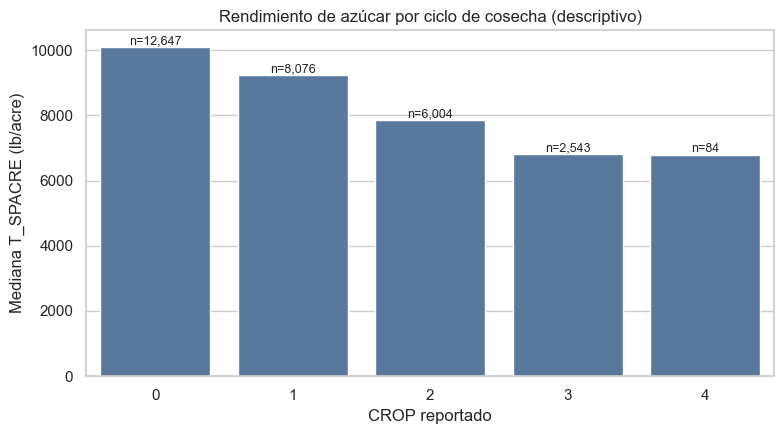

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.5))
plot_data = crop_summary.reset_index().dropna(subset=['CROP_num'])
sns.barplot(data=plot_data, x='CROP_num', y='mediana', color='#4C78A8', ax=ax)
for i, row in plot_data.reset_index(drop=True).iterrows():
    ax.text(i, row['mediana'], f"n={int(row['n']):,}", ha='center', va='bottom', fontsize=9)
ax.set(title='Rendimiento de azúcar por ciclo de cosecha (descriptivo)', xlabel='CROP reportado', ylabel='Mediana T_SPACRE (lb/acre)')
fig.tight_layout()

## Lectura provisional y decisiones para ETL

- La mediana de `T_SPACRE` desciende entre grupos `CROP=0` a `CROP=4`; el grupo 4 es pequeño y la cobertura por etapa es desigual. Analizar después estratos comparables y reportar sus tamaños.
- El valor fuente de `TRS_TON` contiene 10,485 celdas con dos componentes numéricos. El ETL conserva ese texto en `TRS_TON_raw`, separa el prefijo sin interpretarlo y deja el componente numérico final en `TRS_TON` para métricas y modelos.
- El ETL excluye las copias idénticas adicionales y las guarda con su motivo; la primera aparición se mantiene. Las filas con clave candidata repetida y mediciones distintas permanecen para revisión; la auditoría anterior no permite identificar cuál registro conservar.
- `FIBER` tiene cobertura parcial importante. No imputar sin entender por qué falta y en qué etapas/localidades se mide.

La siguiente tarea es ampliar el EDA con métricas de cobertura, rangos y comparaciones justificadas. El ETL conserva columnas originales y campos derivados con trazabilidad; genera un dataset analítico sin copias exactas adicionales, un archivo separado de excluidos con motivo y un reporte de calidad.

## 5. Cobertura y faltantes para el análisis económico

Antes de comparar variedades por contribución por acre, revisamos cuánto respaldo tiene cada `CROP` y dónde faltan mediciones. Los conteos no son comparaciones ajustadas: muestran qué tan sólida puede ser una conclusión por ciclo. En particular, un ciclo con pocas localidades, años o clones no permite recomendar una edad de renovación por sí solo. Se conserva el dataset provisional completo; las filas marcadas para revisión se deben tratar mediante análisis de sensibilidad en la etapa económica.

In [10]:
RUTA_ETL = Path("../data/processed/serie1_etl_provisional.csv")
if not RUTA_ETL.exists():
    RUTA_ETL = Path("data/processed/serie1_etl_provisional.csv")
if not RUTA_ETL.exists():
    raise FileNotFoundError("Ejecuta primero: python scripts/etl_serie1.py")

datos_etl = pd.read_csv(RUTA_ETL, low_memory=False)
variables = ["T_SPACRE", "TCA", "TRS_TON", "POPN", "MSTWT", "FIBER"]
cobertura_crop = datos_etl.groupby("CROP", dropna=False).agg(
    filas=("CROP", "size"),
    clones=("CLONE", "nunique"),
    anios=("YEAR", "nunique"),
    localidades=("LOC", "nunique"),
    etapas=("STAGE", "nunique"),
    filas_marcadas=("REQUIERE_REVISION", "sum"),
)
for variable in variables:
    cobertura_crop[f"faltan_{variable}"] = datos_etl.groupby("CROP", dropna=False)[variable].apply(lambda serie: serie.isna().sum())
display(cobertura_crop)

faltantes = pd.DataFrame({
    "faltantes": datos_etl[variables].isna().sum(),
    "porcentaje": datos_etl[variables].isna().mean().mul(100).round(1),
}).sort_values("porcentaje", ascending=False)
display(faltantes)

print("Filas por etapa y ciclo de cosecha:")
display(datos_etl.groupby(["STAGE", "CROP"]).size().unstack(fill_value=0))

,filas,clones,anios,localidades,etapas,filas_marcadas,faltan_T_SPACRE,faltan_TCA,faltan_TRS_TON,faltan_POPN,faltan_MSTWT,faltan_FIBER
CROP,,,,,,,,,,,,
0,12650,1100,12,32,4,92,61,63,47,1265,77,6731
1,8079,948,12,30,4,83,47,43,20,904,42,4428
2,6038,465,12,29,4,71,58,54,20,809,53,3996
3,2552,38,12,25,3,1,9,6,4,498,20,1669
4,84,13,3,1,1,0,0,0,0,57,0,27


,faltantes,porcentaje
FIBER,16851,57.3
POPN,3533,12.0
MSTWT,192,0.7
T_SPACRE,175,0.6
TCA,166,0.6
TRS_TON,91,0.3


Filas por etapa y ciclo de cosecha:


CROP,0,1,2,3,4
STAGE,,,,,
2,820,903,462,0,0
3,6319,2791,1621,438,0
4,963,506,322,166,0
5,4548,3879,3633,1948,84


## 6. Etapas de selección y escasez de cortes avanzados

`STAGE` identifica la etapa del programa de selección de variedades; `CROP`, el corte desde la plantación. Son dimensiones diferentes. La documentación local no define el protocolo exacto de cada etapa. No interpretar STAGE 5 como quinta cosecha ni como mejor rendimiento garantizado.

Se describe la cobertura del ETL deduplicado, incluyendo filas con alertas, sin filtrar por respuesta. Los conteos de localidades indican presencia, no continuidad de la misma parcela. Para HOCP14-885 se observa plantía en 2018, primera soca desde 2019, segunda desde 2020 y tercera desde 2021: patrón compatible con avance anual y truncamiento al finalizar el archivo. No hay fechas que permitan medir meses entre cortes ni un ID de cohorte que confirme ese seguimiento.

CROP 4 significa quinta cosecha total. Sus 84 filas se concentran en GLENWOOD, 2019–2021; su ausencia durante 2010–2018 incluso para variedades antiguas muestra que la incorporación reciente de una variedad no explica toda la escasez. Diseño/cobertura del ensayo, retiros y pérdida de registros son hipótesis sin causa documentada.

Una regresión de aporte por corte podría resumir asociaciones ajustando por variedad, año y localidad. Antes conviene representar CROP como categoría: una pendiente constante no debe imponerse a priori. Para estudiar diferencias entre socas, separar el cargo único de renovación (1100 USD) del aporte operativo. Una menor contribución por cosecha puede coexistir con un mayor promedio anual por amortización de la renovación. Extrapolar cortes no observados requiere supuestos adicionales y no determina por sí solo el corte óptimo.


In [11]:
from pathlib import Path
import pandas as pd

ruta_cobertura = Path("../data/processed/serie1_etl_provisional.csv")
if not ruta_cobertura.exists():
    ruta_cobertura = Path("data/processed/serie1_etl_provisional.csv")
cobertura_cortes = pd.read_csv(ruta_cobertura, low_memory=False)
etapa_avanzada = cobertura_cortes.loc[cobertura_cortes["STAGE"].eq(5)]

print("Filas por año y CROP en etapa 5, después de deduplicación exacta:")
display(pd.crosstab(etapa_avanzada["YEAR"], etapa_avanzada["CROP"]))
print("Localización de todas las observaciones de CROP 4:")
display(cobertura_cortes.loc[cobertura_cortes["CROP"].eq(4)].groupby(
    ["STAGE", "YEAR", "LOC"]
).agg(filas=("CLONE", "size"), variedades=("CLONE", "nunique")))

# Cada celda cuenta localidades, no parcelas seguidas en el tiempo.
clones_revision = ["HOCP14-885", "HO12-615", "L01-299"]
print("Localidades observadas por variedad, año y CROP:")
display(etapa_avanzada.loc[etapa_avanzada["CLONE"].isin(clones_revision)]
    .groupby(["CLONE", "YEAR", "CROP"])["LOC"].nunique()
    .unstack("CROP", fill_value=0))


Filas por año y CROP en etapa 5, después de deduplicación exacta:


CROP,0,1,2,3,4
YEAR,,,,,
2010,253,234,356,116,0
2011,297,250,258,194,0
2012,358,327,244,141,0
2013,361,265,293,116,0
2014,360,356,288,117,0
2015,429,357,327,160,0
2016,330,323,360,180,0
2017,494,300,296,108,0
2018,447,359,240,135,0


Localización de todas las observaciones de CROP 4:


filas  variedades
STAGE YEAR LOC                        
5     2019 GLENWOOD     27           9
      2020 GLENWOOD     27           9
      2021 GLENWOOD     30          10

Localidades observadas por variedad, año y CROP:


CROP              0   1   2  3  4
CLONE      YEAR                  
HO12-615   2016  11   0   0  0  0
           2017  11  10   0  0  0
           2018  10  10   8  0  0
           2019   9  11  10  9  0
           2020  12   9  11  7  1
           2021  10  12   9  7  1
HOCP14-885 2018  10   0   0  0  0
           2019   9  11   0  0  0
           2020  12   9  11  0  0
           2021  10  12   9  7  0
L01-299    2010   0   0  10  4  0
           2011  10   0   0  6  0
           2012  12  11   0  0  0
           2013  11  10  10  0  0
           2014  12  12  11  4  0
           2015  12  12  11  6  0
           2016  11  12  12  6  0
           2017  11  10  11  4  0
           2018  10  10   8  5  0
           2019   9  11  10  9  1
           2020  12   9  11  7  1
           2021  10  12   9  7  1

## 7. ¿Se observa renovación después de CROP 4?

Se comprueba el rango de CROP en la fuente original y se busca la presencia de otros cortes en la misma variedad/etapa/localidad, en el mismo año y en el siguiente. Este cruce es descriptivo: NO reconstruye transiciones de parcela. El ETL convierte CROP a entero sin recodificarlo ni limitar su máximo.

La fuente solo contiene CROP 0–4. Las 84 filas CROP 4 corresponden a 28 combinaciones de variedad/etapa/localidad/año: 18 de 2019–2020 y 10 de 2021. En 8 de las 18 primeras se observa CROP 0 al año siguiente con igual variedad/etapa/localidad; no prueba renovación de la misma parcela. En 25 de las 28 combinaciones ya coexiste algún CROP inferior en el mismo año, lo que impide identificar el estado de una única plantación por esa clave.

Conclusión: el cierre del archivo puede limitar los cortes de variedades recientes, pero no demuestra por sí solo por qué faltan CROP 5 en cohortes anteriores. No hay ID de parcela/cohorte, fecha de renovación o causa de retiro que permita separar renovación deliberada, límite del protocolo de seguimiento o registros no incluidos. No asignar aporte cero ni pérdida a cortes no observados. CROP 4 es quinta cosecha; CROP 5 sería sexta. La expectativa de retorno de esta última, si se modela, será extrapolación sin una cosecha de ese nivel para contrastarla.


In [12]:
from pathlib import Path
import pandas as pd

raiz_revision = Path("..") if Path("../data/raw").exists() else Path(".")
fuente_cortes = pd.read_csv(raiz_revision / "data/raw/louisiana_sugarcane_2010_2021.csv", dtype=str, keep_default_na=False)
print("CROP tal como aparece en el CSV original:")
display(fuente_cortes["CROP"].value_counts().sort_index().rename("filas"))

base_cortes = pd.read_csv(raiz_revision / "data/processed/serie1_etl_provisional.csv", low_memory=False)
claves_cortes = ["CLONE", "STAGE", "LOC", "YEAR"]
presencia_cortes = base_cortes[claves_cortes + ["CROP"]].drop_duplicates()
cuarta_soca = presencia_cortes.loc[presencia_cortes["CROP"].eq(4), claves_cortes].copy()
cuarta_soca["YEAR_SIGUIENTE"] = cuarta_soca["YEAR"] + 1
posteriores = presencia_cortes.rename(columns={"YEAR": "YEAR_SIGUIENTE", "CROP": "CROP_ANIO_SIGUIENTE"})
cruce_posterior = cuarta_soca.merge(posteriores, on=["CLONE", "STAGE", "LOC", "YEAR_SIGUIENTE"], how="left")
print("Presencia al año siguiente: no son transiciones identificadas de parcela.")
display(cruce_posterior.groupby(claves_cortes)["CROP_ANIO_SIGUIENTE"].agg(
    lambda s: ", ".join(str(int(x)) for x in sorted(s.dropna().unique())) or "Sin registros"
).rename("CROPS_OBSERVADOS_ANIO_SIGUIENTE"))

previas_cierre = cuarta_soca.loc[cuarta_soca["YEAR"].lt(base_cortes["YEAR"].max())]
con_plantia = cruce_posterior.loc[cruce_posterior["CROP_ANIO_SIGUIENTE"].eq(0), claves_cortes].drop_duplicates()
coexistentes = cuarta_soca.merge(presencia_cortes.loc[presencia_cortes["CROP"].lt(4)], on=claves_cortes)[claves_cortes].drop_duplicates()
print(f"Combinaciones CROP 4: {len(cuarta_soca)}; anteriores al cierre: {len(previas_cierre)}.")
print(f"Con plantía al año siguiente, sin identidad de parcela: {len(con_plantia)}.")
print(f"Con otros CROP en el mismo año: {len(coexistentes)} de {len(cuarta_soca)}.")


CROP tal como aparece en el CSV original:


CROP
0    12708
1     8123
2     6062
3     2552
4       84
Name: filas, dtype: int64

Presencia al año siguiente: no son transiciones identificadas de parcela.


CLONE       STAGE  LOC       YEAR
HO07-613    5      GLENWOOD  2019                4
                             2020    Sin registros
HO11-573    5      GLENWOOD  2021    Sin registros
HO12-615    5      GLENWOOD  2020       0, 1, 3, 4
                             2021    Sin registros
HO13-739    5      GLENWOOD  2021    Sin registros
HOCP00-950  5      GLENWOOD  2019    Sin registros
HOCP04-838  5      GLENWOOD  2019          2, 3, 4
                             2020             3, 4
                             2021    Sin registros
HOCP09-804  5      GLENWOOD  2019       0, 2, 3, 4
                             2020       0, 1, 3, 4
                             2021    Sin registros
HOCP96-540  5      GLENWOOD  2019       0, 2, 3, 4
                             2020          1, 3, 4
                             2021    Sin registros
L01-283     5      GLENWOOD  2019          2, 3, 4
                             2020             3, 4
                             2021    Sin registr

Combinaciones CROP 4: 28; anteriores al cierre: 18.
Con plantía al año siguiente, sin identidad de parcela: 8.
Con otros CROP en el mismo año: 25 de 28.
